In [2]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_raw, add_target, get_X_y
from src.models import get_models
from src.evaluate import make_estimator
from src.explain import coefficient_table, cv_permutation_importance, explain_student
from src.config import FIGURES_DIR

SCENARIO, MODEL = "b_G1_only", "Logistic Regression"   # chosen in Stage 4

df = add_target(load_raw("por"))
X, y = get_X_y(df, SCENARIO)

model, scale, grid = get_models()[MODEL]
search = make_estimator(model, scale, grid, X).fit(X, y)
final_model = search.best_estimator_      # a plain Pipeline: prep + LogisticRegression
print("Best params:", search.best_params_)

Best params: {'model__C': 1.0}


In [3]:
coefs = coefficient_table(final_model)
coefs.head(15).round(3)

,feature,coef,odds_ratio,direction
13,G1,-3.495,0.030,lowers risk
24,Fjob_at_home,-1.168,0.311,lowers risk
28,Fjob_teacher,1.092,2.981,raises risk
14,school_MS,1.020,2.773,raises risk
0,age,-0.652,0.521,lowers risk
41,higher_yes,-0.533,0.587,lowers risk
5,failures,0.524,1.689,raises risk
11,health,0.438,1.549,raises risk
21,Mjob_other,0.330,1.392,raises risk
42,internet_yes,0.325,1.384,raises risk


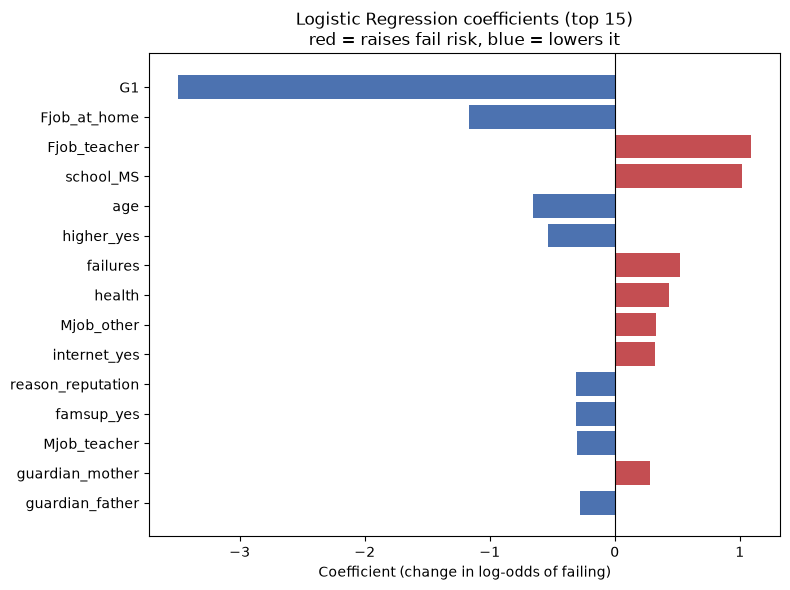

In [4]:
top = coefs.head(15).iloc[::-1]   # reverse so the biggest is at the top of the chart
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["feature"], top["coef"],
        color=["#C44E52" if c > 0 else "#4C72B0" for c in top["coef"]])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Logistic Regression coefficients (top 15)\nred = raises fail risk, blue = lowers it")
ax.set_xlabel("Coefficient (change in log-odds of failing)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_coefficients.png", dpi=150)
plt.show()

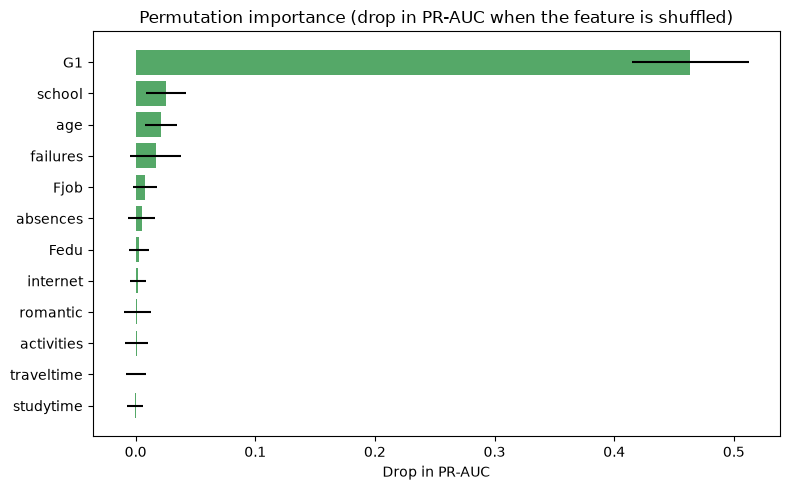

,feature,importance,std
0,G1,0.4635,0.0489
1,school,0.0256,0.0167
2,age,0.0213,0.0133
3,failures,0.0167,0.0213
4,Fjob,0.0078,0.0097
5,absences,0.0049,0.0115
6,Fedu,0.0027,0.0085
7,internet,0.0018,0.0065
8,romantic,0.0014,0.0112
9,activities,0.0009,0.0097


In [5]:
perm = cv_permutation_importance(final_model, X, y)

top_perm = perm.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_perm["feature"], top_perm["importance"], xerr=top_perm["std"], color="#55A868")
ax.set_title("Permutation importance (drop in PR-AUC when the feature is shuffled)")
ax.set_xlabel("Drop in PR-AUC")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_permutation_importance.png", dpi=150)
plt.show()

perm.head(12).round(4)

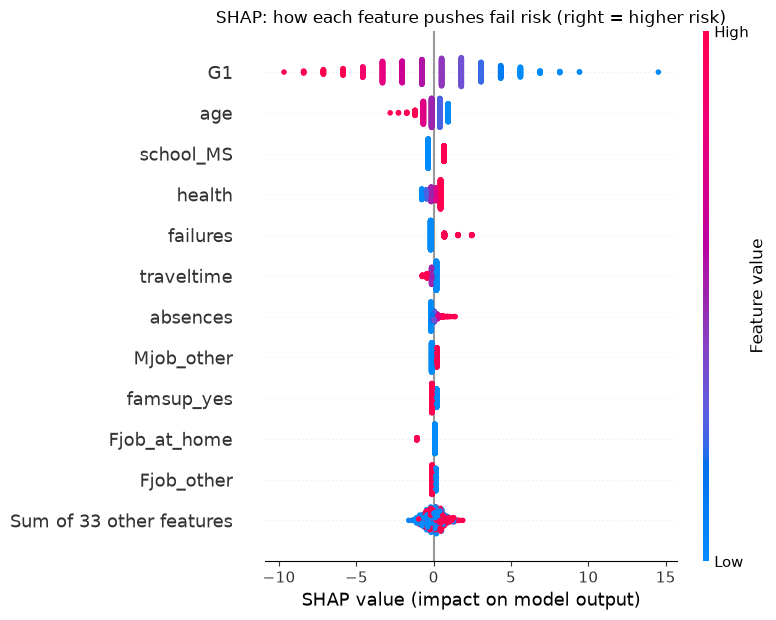

In [6]:
import shap

prep = final_model.named_steps["prep"]
X_ready = prep.transform(X)
feature_names = prep.get_feature_names_out()

# Use ALL students as the "average" reference (default would subsample 100)
masker = shap.maskers.Independent(X_ready, max_samples=len(X_ready))
explainer = shap.LinearExplainer(final_model.named_steps["model"], masker)
shap_values = explainer(X_ready)
shap_values.feature_names = list(feature_names)

shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title("SHAP: how each feature pushes fail risk (right = higher risk)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "12_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
probs = final_model.predict_proba(X)[:, 1]   # fail probability for every student

examples = {
    "Highest risk":       int(np.argmax(probs)),
    "Borderline (~50%)":  int(np.argmin(np.abs(probs - 0.5))),
    "Lowest risk":        int(np.argmin(probs)),
}
for label, i in examples.items():
    print(f"\n=== {label}: fail probability = {probs[i]:.0%} ===")
    print(explain_student(final_model, X.iloc[[i]], X).round(2).to_string(index=False))


=== Highest risk: fail probability = 100% ===
feature   value  contribution      effect
     G1       0         14.52 raises risk
   Fjob teacher          1.20 raises risk
    age      18         -0.67 lowers risk

=== Borderline (~50%): fail probability = 50% ===
 feature value  contribution      effect
      G1    10          1.78 raises risk
failures     1          0.69 raises risk
  school    MS          0.66 raises risk

=== Lowest risk: fail probability = 0% ===
feature   value  contribution      effect
     G1      18         -8.41 lowers risk
   Fjob at_home         -1.06 lowers risk
    age      18         -0.67 lowers risk


In [ ]:
## Explainability conclusions

'''- **G1 dominates:** shuffling it drops PR-AUC by ~0.46; every other feature < 0.03.
- **Other consistent risk factors:** attending school MS, past class failures
  (raise risk), wanting higher education (lowers risk).
- **Rare categories mislead:** `Fjob` has large coefficients but near-zero
  permutation importance, because only ~40 students per category. Coefficients
  must be checked against permutation importance.
- **Per-student reasons** use coefficient × (value − average), which equals SHAP
  for a linear model. This powers the "top 3 reasons" in the app.
- These are associations, not causes: the tool says *who* to check on, not *why*.'''